# Resource estimation with `ResourceEstimator`

This notebook revisits the Q#, Cirq, QIR, and OpenQASM inputs from [Importing Quantum Programs](1_qre_input.ipynb), but uses the stateful `ResourceEstimator` API. It also loads a dollar-cost specification from a JSON file and attaches it with `set_cost_model`, so every result includes an estimated cost.

In [1]:
from pathlib import Path

import cirq
import qdk

from qiskit.circuit.library import RGQFTMultiplier
from qiskit.qasm3.exporter import Exporter

from qdk.qre import CompilationStrategy, LatticeSurgery, PSSPC, ResourceEstimator, plot_estimates
from qdk.qre.application import CirqApplication, OpenQASMApplication, QIRApplication, QSharpApplication
from qdk.qre.dollar_cost import DollarCostModelFromSpec
from qdk.qre.models import GateBased, RoundBasedFactory, SurfaceCode

## Create applications from four input formats

Each wrapper produces the same `Application` abstraction expected by `ResourceEstimator`, regardless of the source language or framework.

### Q#

Define an inline Q# ripple-carry adder and wrap the compiled entry point.

In [2]:
%%qsharp

import Std.Arithmetic.*;

operation Program(n : Int) : Unit {
    use a = Qubit[n];
    use b = Qubit[n];

    RippleCarryCGIncByLE(a, b);
}

In [3]:
qsharp_app = QSharpApplication(qdk.code.Program, args=(10,))  # type: ignore

### Cirq

Build a 10-qubit QFT circuit with Cirq.

In [4]:
circuit = cirq.Circuit(cirq.qft(*cirq.LineQubit.range(10)))
cirq_app = CirqApplication(circuit)

### QIR

Load a precompiled Hidden Shift program from an LLVM IR file.

In [5]:
qir_file = (
    Path.cwd().parent.parent
    / "source" / "qdk_package" / "tests-integration" / "resources"
    / "adaptive_ri" / "output" / "HiddenShiftNISQ.ll"
)
qir_app = QIRApplication(qir_file.read_text(encoding="utf-8"))

### OpenQASM

Export a Qiskit RGQFT multiplier to OpenQASM 3.

In [6]:
source = Exporter().dumps(RGQFTMultiplier(num_state_qubits=4))
qasm_app = OpenQASMApplication(source)

## Configure `ResourceEstimator`

Unlike the functional `estimate` API, `ResourceEstimator` is configured one component at a time:

- `set_qpu` selects the physical architecture.
- `add_compilation_strategy` adds a trace-transform pipeline.
- `add_code` adds the error-correction implementation.
- `add_factory` adds the magic-state factory implementation.
- `options.max_error` sets the total error budget.

In [7]:
strategy = CompilationStrategy()
strategy.add_pass(PSSPC.q())
strategy.add_pass(LatticeSurgery.q())

estimator = ResourceEstimator()
estimator.set_qpu(GateBased(gate_time=100, measurement_time=500))
estimator.add_compilation_strategy(strategy)
estimator.add_code(SurfaceCode.q())
estimator.add_factory(RoundBasedFactory.q())
estimator.options.max_error = 0.01

## Load and attach a dollar-cost model

`DollarCostModelFromSpec` loads the hardware lifetime, utilization, capital-cost, and operating-cost assumptions from `example_cost_spec.json`. Passing the model to `set_cost_model` makes the estimator add a `USD cost` column to every result table.

In [8]:
cost_spec_path = Path("example_cost_spec.json")
cost_model = DollarCostModelFromSpec(str(cost_spec_path))
estimator.set_cost_model(cost_model)

## Estimate each application

`estimate` returns a `ResourceEstimationResult`. Its `estimation_table` contains the Pareto-optimal estimates, including the dollar-cost column added by the configured cost model.

In [9]:
applications = [
    ("Q# adder", qsharp_app),
    ("Cirq QFT", cirq_app),
    ("QIR Hidden Shift", qir_app),
    ("OpenQASM multiplier", qasm_app),
]

results = [estimator.estimate(app, name=name) for name, app in applications]
tables = [result.estimation_table for result in results]

Display logical counts

In [10]:
for result in results:
    print(result.logical_counts)

{'compute_qubits': 30, 'memory_qubits': None, 'total_qubits': 30, 'depth': 18, 'num_gates': 18, 'gates': {'CCX': 9, 'MEAS_Z': 9}}
{'compute_qubits': 10, 'memory_qubits': None, 'total_qubits': 10, 'depth': 191, 'num_gates': 240, 'gates': {'H': 10, 'T_DAG': 9, 'T': 18, 'SWAP': 5, 'RZ': 108, 'CZ': 90}}
{'compute_qubits': 6, 'memory_qubits': None, 'total_qubits': 6, 'depth': 8, 'num_gates': 34, 'gates': {'H': 18, 'MEAS_RESET_Z': 6, 'PAULI_X': 4, 'CZ': 6}}
{'compute_qubits': 16, 'memory_qubits': None, 'total_qubits': 16, 'depth': 509, 'num_gates': 672, 'gates': {'T': 140, 'RZ': 532}}


Display one result table to inspect its qubit, runtime, and cost estimates.

In [11]:
tables[0].as_frame()

,name,qubits,runtime,error,USD cost
0,Q# adder,3774,0 days 00:00:00.000180,0.003683,0.0
1,Q# adder,7429,0 days 00:00:00.000108,0.009083,0.0


Plot the Pareto frontiers returned for all four input formats.

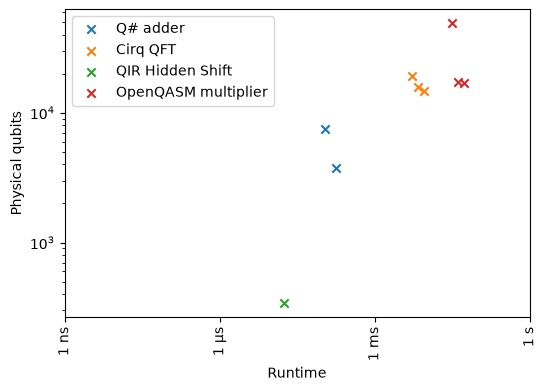

In [12]:
plot_estimates(tables, figsize=(6, 4))